# A deep mutational scan with PyroPPI

PPI Recorder records a protein-protein interaction as an edit on an RNA reporter.
One protein of interest is fused to the adenine base editor ABE8e and the other to the MS2 coat protein MCP, and both are expressed from a single plasmid together with a barcoded reporter RNA carrying an MS2 hairpin.
MCP holds the reporter.
When the two proteins come close enough, the editor reaches the adenines in the reporter and deaminates them, and amplicon sequencing reads the edits back.
The measurement is the fraction of reporter reads that carry an edit, and the barcode says which pair of proteins produced it.
Every pair is measured in the same pool of cells, so thousands of pairs can be read at once.

A deep mutational scan replaces one protein of the pair with a library of single-amino-acid substitutions, so every variant is measured against the same wild-type partner in the same pool.
This vignette works through one scan end to end: load the counts, apply the read floor, fit PyroPPI, separate the variant classes, call variants against the synonymous null, lay the calls out along the sequence, and ask whether they sit near the binding interface.

The worked example is RAD51D, scanned against wild-type XRCC2.
The two form one arm of the BCDX2 complex, a RAD51-paralog subcomplex that acts in homologous recombination.
The reciprocal scan of XRCC2 against wild-type RAD51D runs beside it as a comparison.
Variant constructs are named `GENE:A63E`, giving the reference residue, the position and the substitution; a synonymous variant reads `RAD51D:A121A` and a stop-gain reads `RAD51D:R12*`.

In [1]:
import os
import time
from pathlib import Path

os.environ.setdefault("TQDM_DISABLE", "1")  # keep the fitting progress bar out of the notebook

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as sstats

from pyroppi import fit, load_fit, read_dataset
from pyroppi import stats as ps
from pyroppi.data import apply_read_floor
from pyroppi.plotting import COLORS

# The manuscript palette: green, amber and grey name the three variant classes,
# vermilion marks a called variant, blue separates the two scans and pink marks
# a Walker motif.
SYN, STOP, MIS = COLORS["synonymous"], COLORS["stop_gain"], COLORS["missense"]
HIT, WALKER, BLUE = COLORS["hit"], COLORS["walker_motif"], "#0072B2"
CLASS_COLOR = {"synonymous": SYN, "missense": MIS, "stop": STOP}
ORDER = ["synonymous", "missense", "stop"]

DRUG = ["3h", "U2OS_x_3h"]  # the condition block
CELL = ["U2OS"]             # the cell block
MIN_READS = 20              # the read floor
ALPHA = 0.05                # the one-tailed hit-calling threshold
DEPTH_LABEL_AT = 3.45       # where the two depth histograms are well separated
STEPS = 60_000              # SVI steps, the number the manuscript fits used
DRAWS, SEED = 20_000, 0     # the run-replacement null


def find_repo(start):
    """Walk up from `start` to the repository root."""
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "annotations" / "variants.csv").exists():
            return candidate
    raise FileNotFoundError(f"no data/ directory above {start}")


REPO = find_repo(Path.cwd())
DATA, RESULTS = REPO / "data", REPO / "results"

plt.rcParams.update({
    "figure.dpi": 150, "font.size": 8, "axes.titlesize": 9,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})


def box(ax, position, values, color, width=0.55):
    """One box at `position`, coloured throughout."""
    artists = ax.boxplot([values], positions=[position], widths=width,
                         showfliers=False, patch_artist=True)
    artists["boxes"][0].set(facecolor=color, alpha=0.35, edgecolor=color, linewidth=1.0)
    for part in ("whiskers", "caps"):
        for line in artists[part]:
            line.set(color=color, linewidth=1.0)
    artists["medians"][0].set(color=color, linewidth=1.8)


def count_labels(ax, counts, colors):
    """Write the group sizes in a strip of blank axes below the boxes."""
    low, high = ax.get_ylim()
    ax.set_ylim(low - 0.13 * (high - low), high)
    for position, (n, color) in enumerate(zip(counts, colors)):
        ax.text(position, 0.015, f"n={n:,}", transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=6.5, color=color)


DATA

PosixPath('/data/pinello/USER_PROJECTS/ji111/PyroPPI/data')

## 1. The library and its read depth

A PyroPPI dataset is two plain tables.
`counts.csv` has one row for every sample and every measured pair: the `bait` is the ABE8e fusion, the `prey` is the MCP fusion, `total` is the number of reporter reads assigned to that pair in that sample, and `edited` is how many of those reads carry an edit.
`samples.csv` has one row per sample, with the descriptive columns parsed out of the sample name and then the binary design columns the model reads.

Each scan carries its variant library on MCP and measures it against several wild-type baits in the same pool.
`pyroppi.stats.parse_variants` splits the construct names into gene, reference residue, position and substitution, and labels each one synonymous, missense or stop-gain.

In [2]:
SCANS = {
    "RAD51D": {"dataset": "dms_rad51d", "partner": "XRCC2"},
    "XRCC2": {"dataset": "dms_xrcc2", "partner": "RAD51D"},
}
for gene, scan in SCANS.items():
    scan["counts"], scan["samples"] = read_dataset(DATA / scan["dataset"])
    scan["library"] = ps.parse_variants(scan["counts"]["prey"].unique())

rad51d = SCANS["RAD51D"]
rad51d["counts"].head()

,sample,bait,prey,total,edited
0,HCT_RAD51D_DMS_RepA_0h,RAD51C,RAD51D:A121A,367,13
1,HCT_RAD51D_DMS_RepA_0h,RAD51C,RAD51D:A121E,85,5
2,HCT_RAD51D_DMS_RepA_0h,RAD51C,RAD51D:A121G,248,44
3,HCT_RAD51D_DMS_RepA_0h,RAD51C,RAD51D:A121P,172,47
4,HCT_RAD51D_DMS_RepA_0h,RAD51C,RAD51D:A121R,539,31


In [3]:
rad51d["samples"]

,sample,cell_line,treatment,replicate,3h,U2OS_x_3h,U2OS
0,HCT_RAD51D_DMS_RepA_0h,HCT116,rapamycin_0h,A,0,0,0
1,HCT_RAD51D_DMS_RepA_3h,HCT116,rapamycin_3h,A,1,0,0
2,HCT_RAD51D_DMS_RepB_0h,HCT116,rapamycin_0h,B,0,0,0
3,HCT_RAD51D_DMS_RepB_3h,HCT116,rapamycin_3h,B,1,0,0
4,HCT_RAD51D_DMS_RepC_0h,HCT116,rapamycin_0h,C,0,0,0
5,HCT_RAD51D_DMS_RepC_3h,HCT116,rapamycin_3h,C,1,0,0
6,HCT_RAD51D_DMS_RepD_0h,HCT116,rapamycin_0h,D,0,0,0
7,HCT_RAD51D_DMS_RepD_3h,HCT116,rapamycin_3h,D,1,0,0
8,HCT_RAD51D_DMS_RepE_0h,HCT116,rapamycin_0h,E,0,0,0
9,HCT_RAD51D_DMS_RepE_3h,HCT116,rapamycin_3h,E,1,0,0


Twenty samples: five replicates in each of two cell lines, HCT116 and U2OS, each replicate harvested with no rapamycin and after three hours of rapamycin.
The three design columns encode that layout. `3h` is on in every three-hour sample, `U2OS` is on in every U2OS sample, and `U2OS_x_3h` is on where both hold, which is the interaction term that lets the rapamycin shift differ between the two cell lines.
The untreated HCT116 arm has all three off, so it is the reference the pair baseline describes.

In [4]:
for gene, scan in SCANS.items():
    counts, library = scan["counts"], scan["library"]
    missense = library[library["class"] == "missense"]
    print(
        f"{gene}: {len(counts):,} rows, {len(scan['samples'])} samples, "
        f"{counts['prey'].nunique():,} constructs over "
        f"{missense['position'].nunique()} substituted positions "
        f"({missense['position'].min()} to {missense['position'].max()}), "
        f"median depth {counts['total'].median():,.0f} reads"
    )
    print("    " + ", ".join(f"{n:,} {name}" for name, n
                             in library["class"].value_counts().items())
          + f", baits {', '.join(sorted(counts['bait'].unique()))}")

RAD51D: 141,515 rows, 20 samples, 1,771 constructs over 305 substituted positions (4 to 326), median depth 552 reads
    1,629 missense, 87 synonymous, 55 stop, baits RAD51C, XRCC2, XRCC3, mCherry
XRCC2: 111,724 rows, 20 samples, 1,409 constructs over 259 substituted positions (4 to 278), median depth 532 reads
    1,263 missense, 77 synonymous, 69 stop, baits RAD51D, XRCC2, XRCC3, mCherry


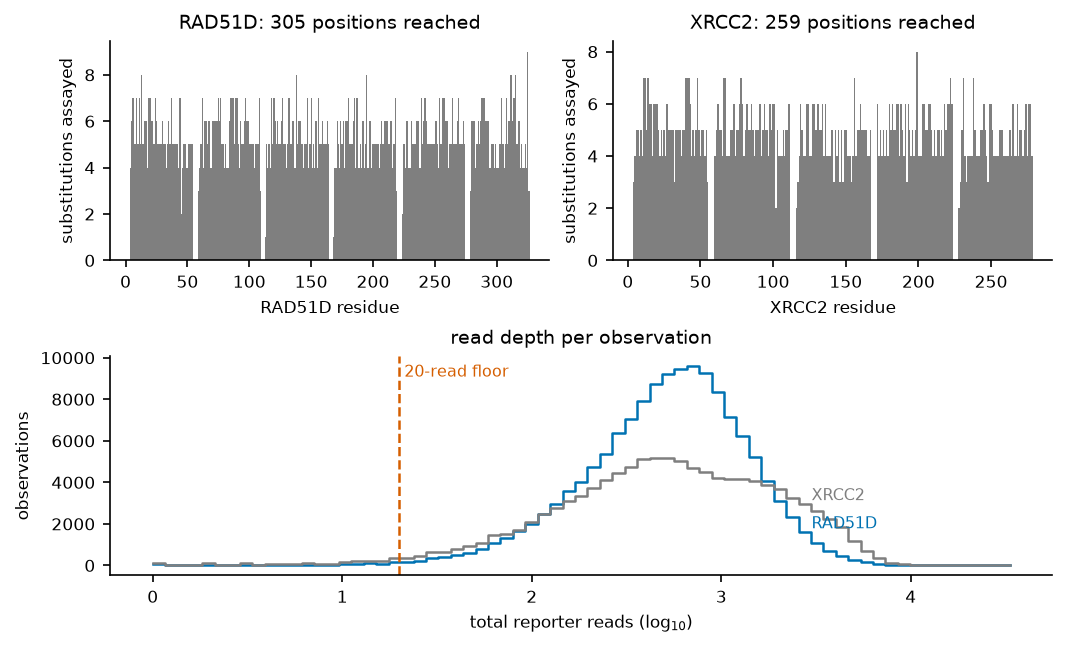

In [5]:
figure, axes = plt.subplot_mosaic([["RAD51D", "XRCC2"], ["depth", "depth"]],
                                  figsize=(7.0, 4.2), constrained_layout=True)
for gene, scan in SCANS.items():
    library = scan["library"]
    per_position = library[library["class"] == "missense"].groupby("position").size()
    axes[gene].bar(per_position.index, per_position.to_numpy(), width=1.0, color=MIS)
    axes[gene].set(xlabel=f"{gene} residue", ylabel="substitutions assayed",
                   title=f"{gene}: {len(per_position)} positions reached")

# Shared bins, so the two histograms can be read against each other, and a
# label placed on each curve where the two are well separated.
depth = {gene: np.log10(scan["counts"]["total"]) for gene, scan in SCANS.items()}
bins = np.linspace(min(values.min() for values in depth.values()),
                   max(values.max() for values in depth.values()), 71)
for gene, values in depth.items():
    colour = BLUE if gene == "RAD51D" else MIS
    heights, edges = np.histogram(values, bins=bins)
    axes["depth"].step(edges[:-1], heights, where="post", color=colour, linewidth=1.2)
    at = min(np.searchsorted(edges, DEPTH_LABEL_AT) - 1, len(heights) - 1)
    axes["depth"].text(DEPTH_LABEL_AT, heights[at], f" {gene}", color=colour,
                       va="bottom", fontsize=7.5)
axes["depth"].axvline(np.log10(MIN_READS), color=HIT, linestyle="--", linewidth=1.2)
axes["depth"].text(np.log10(MIN_READS), axes["depth"].get_ylim()[1] * 0.96,
                   f" {MIN_READS}-read floor", color=HIT, va="top", fontsize=7.5)
axes["depth"].set(xlabel="total reporter reads (log$_{10}$)", ylabel="observations",
                  title="read depth per observation")
plt.show()

The top row is the coverage of each library.
Most residues the library reaches carry four to eight substitutions, and blocks of each protein are missing entirely where the synthesis or the cloning did not deliver.
The gaps fall in contiguous blocks, which is one reason the structural test in section 8 needs a null that respects runs along the chain.

The depth histogram is wide, which is the usual shape for a pooled screen.
Abundance in the plasmid pool varies over orders of magnitude, so a few constructs are read tens of thousands of times and a few only once.
The dashed line is the read floor the next section applies.

## 2. The 20-read floor

An editing fraction computed on three reads carries almost no information, and feeding it to a Binomial likelihood as though it did lets a handful of reads move a variant's estimate.
PyroPPI therefore applies a read floor, 20 reads by default, and `pyroppi.data.apply_read_floor` is the function the model calls.

The floor censors rather than deletes.
An observation below the floor stays in the table with `used` set to False, so it does not enter the likelihood, and the other replicates of the same variant are untouched.
Only when every observation of a measured pair falls below the floor is the pair dropped, because then its estimate would be the prior alone.

Both of these scans have sub-floor observations, so the two behaviours are visible rather than hypothetical.

RAD51D: 721 of 141,515 observations sit below the 20-read floor, in 258 of 1,771 constructs; 699 of them are censored inside 263 measured pairs that keep other replicates, and 6 measured pairs of 7,083 lose every observation and are dropped


XRCC2: 1,855 of 111,724 observations sit below the 20-read floor, in 457 of 1,409 constructs; 1,849 of them are censored inside 593 measured pairs that keep other replicates, and 3 measured pairs of 5,598 lose every observation and are dropped


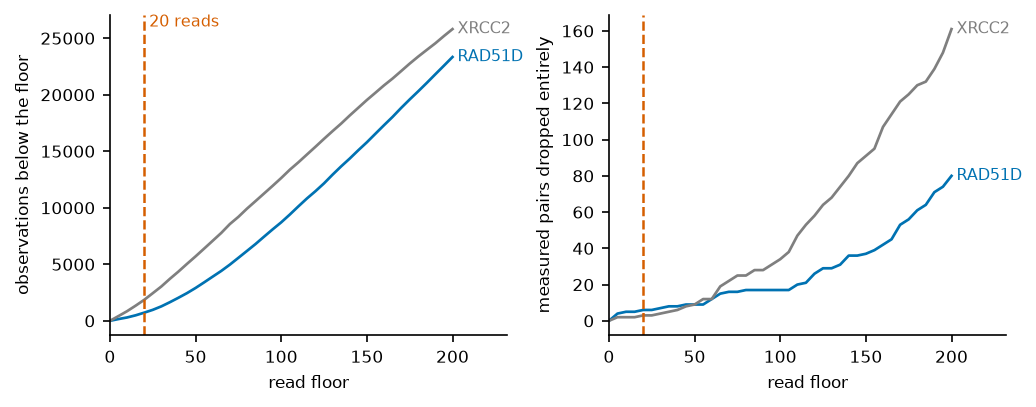

In [6]:
floors = np.arange(0, 205, 5)
figure, axes = plt.subplots(1, 2, figsize=(6.8, 2.6), constrained_layout=True)

for gene, scan in SCANS.items():
    counts = scan["counts"]
    measured = counts.groupby(["bait", "prey"]).ngroups
    scan["kept"] = apply_read_floor(counts, MIN_READS)
    censored = int((~scan["kept"]["used"]).sum())
    dropped = measured - scan["kept"].groupby(["bait", "prey"]).ngroups
    touched = int(scan["kept"].groupby(["bait", "prey"])["used"]
                  .apply(lambda used: (~used).any()).sum())
    print(
        f"{gene}: {int((counts['total'] < MIN_READS).sum()):,} of {len(counts):,} "
        f"observations sit below the {MIN_READS}-read floor, in "
        f"{counts.loc[counts['total'] < MIN_READS, 'prey'].nunique()} of "
        f"{counts['prey'].nunique():,} constructs; {censored:,} of them are censored "
        f"inside {touched} measured pairs that keep other replicates, and {dropped} "
        f"measured pairs of {measured:,} lose every observation and are dropped"
    )

    # A pair is dropped entirely when its deepest observation is below the floor.
    deepest = counts.groupby(["bait", "prey"])["total"].max().to_numpy()
    colour = BLUE if gene == "RAD51D" else MIS
    series = [(counts["total"].to_numpy()[None, :] < floors[:, None]).sum(axis=1),
              (deepest[None, :] < floors[:, None]).sum(axis=1)]
    for axis, values in zip(axes, series):
        axis.plot(floors, values, color=colour, linewidth=1.3)
        axis.text(floors[-1], values[-1], f" {gene}", color=colour, va="center",
                  fontsize=7.5)

for axis, label in zip(axes, ["observations below the floor",
                              "measured pairs dropped entirely"]):
    axis.axvline(MIN_READS, color=HIT, linestyle="--", linewidth=1.2)
    axis.set(xlabel="read floor", ylabel=label, xlim=(0, 232))
axes[0].text(MIN_READS, axes[0].get_ylim()[1], f" {MIN_READS} reads", color=HIT,
             va="top", fontsize=7.5)
plt.show()

At 20 reads the floor is gentle.
It censors 0.5% of the RAD51D observations and 1.7% of the XRCC2 observations, and it costs six measured pairs in the first scan and three in the second.
Both curves climb steeply beyond that, which is the trade the default setting makes: a higher floor buys cleaner observations and starts deleting whole variants, and at 200 reads it would drop eighty RAD51D pairs and a hundred and sixty-one XRCC2 pairs.

Censoring also explains why the sub-floor count in the table and the censored count in the fit differ slightly.
Twenty-two RAD51D observations and six XRCC2 observations sit inside the pairs that lose everything, so they leave with their pairs instead of being censored in place.

## 3. Fitting the model

PyroPPI models the edited read count of each observation as Binomial in its total, with the editing probability given on the log-odds scale by a sum of three blocks: a per-pair interaction baseline, drug or condition shifts, and cell-type shifts.
Each block is estimated per canonical pair, so every variant gets its own baseline and its own response to each covariate.

The three blocks map onto the design of this scan directly.
The pair term is the log-odds of editing in the reference arm, HCT116 with no rapamycin, so a variant's baseline is what the untreated HCT116 replicates say about it.
The `3h` coefficient is what three hours of rapamycin adds on top of that baseline, `U2OS` is what the second cell line adds, and `U2OS_x_3h` is the extra shift carried by samples that are both.
All three are binary indicators, so none of them is a slope on a dose or on a time; the model knows only whether a condition was on.

The baselines are drawn from a shared normal whose centre and width are themselves estimated, which is what partial pooling means here.
A variant with little information of its own is pulled towards the population of variants, and a variant measured deeply and consistently is left close to what its own reads say.
The practical effect is that noisy variants do not produce extreme estimates simply by being noisy.

The fit uses stochastic variational inference with a mean-field normal guide in place of MCMC, so the convergence check is the ELBO loss curve rather than a trace plot or an R-hat.
Sixty thousand steps over 141,515 observations take a little over a minute on a GPU.

In [7]:
start = time.perf_counter()
rad51d["fit"] = fit(
    rad51d["counts"], rad51d["samples"],
    drug=DRUG, cell=CELL,
    baseline=True,            # the untreated HCT116 arm anchors the pair term
    min_reads=MIN_READS, num_steps=STEPS, seed=SEED,
)
print(f"RAD51D: {STEPS:,} steps in {time.perf_counter() - start:.0f} s, "
      f"final ELBO {rad51d['fit'].losses[-1]:,.0f}, "
      f"{len(rad51d['fit'].canonical):,} canonical pairs")

Fitting:   0%|          | 0/60000 [00:00<?, ?it/s]

RAD51D: 60,000 steps in 75 s, final ELBO 3,023,163, 7,077 canonical pairs


The XRCC2 scan is the same size and takes about as long, so rather than fit it here the vignette reads the saved fit.
`scripts/fit_all.py` wrote it with the same settings this cell just used: the same two drug columns, the same cell column, the same 20-read floor and the same 60,000 steps.
`pyroppi.load_fit` restores the posterior draws, the loss trace and those settings, so the comparison below is drawn from an identical recipe.

In [8]:
xrcc2 = SCANS["XRCC2"]
xrcc2["fit"] = load_fit(RESULTS / xrcc2["dataset"])
print(f"XRCC2: {len(xrcc2['fit'].losses):,} steps, "
      f"final ELBO {xrcc2['fit'].losses[-1]:,.0f}, "
      f"drug={xrcc2['fit'].drug}, cell={xrcc2['fit'].cell}, "
      f"min_reads={xrcc2['fit'].min_reads}")

effects = rad51d["fit"].effects()
print("\nRAD51D covariate shifts in log-odds, over the canonical pairs")
print(effects.groupby("covariate")["logit_mean"].agg(["mean", "min", "max"])
      .loc[DRUG + CELL].to_string())

XRCC2: 60,000 steps, final ELBO 2,668,708, drug=['3h', 'U2OS_x_3h'], cell=['U2OS'], min_reads=20



RAD51D covariate shifts in log-odds, over the canonical pairs
               mean       min       max
covariate                              
3h         0.509677 -2.437580  4.493201
U2OS_x_3h  0.012449 -4.114232  4.204960
U2OS       0.787799 -2.424243  3.813949


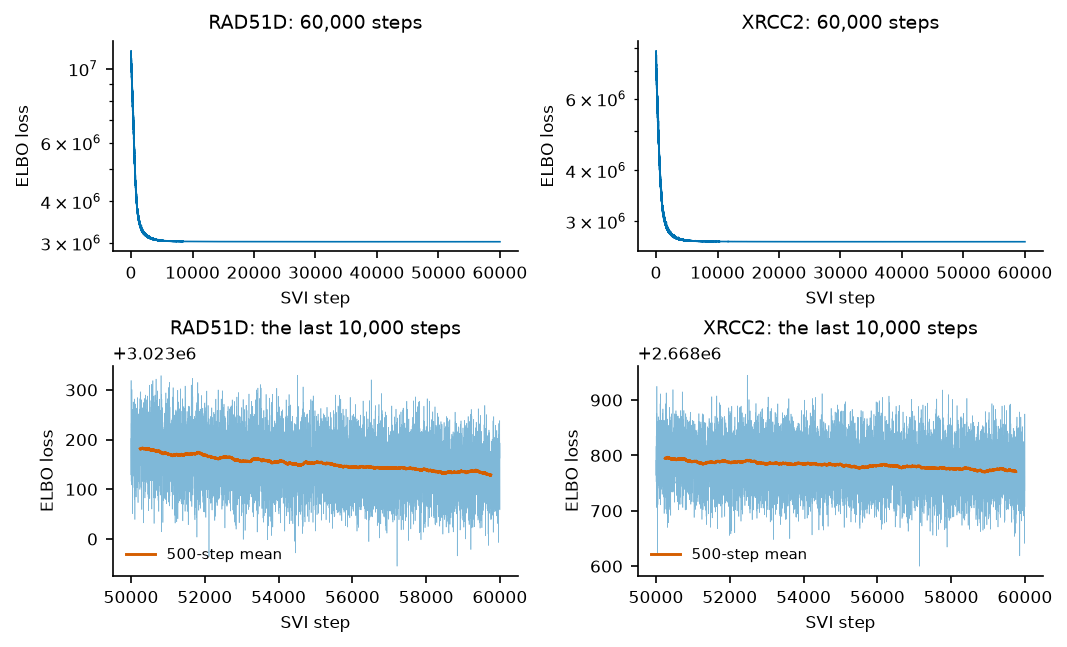

In [9]:
figure, axes = plt.subplots(2, 2, figsize=(7.0, 4.2), constrained_layout=True)
for column, (gene, scan) in enumerate(SCANS.items()):
    losses = scan["fit"].losses
    step = np.arange(1, len(losses) + 1)
    tail = min(10_000, len(losses))
    axes[0, column].plot(step, losses, color=BLUE, linewidth=0.8)
    axes[0, column].set(xlabel="SVI step", ylabel="ELBO loss", yscale="log",
                        title=f"{gene}: {len(losses):,} steps")
    axes[1, column].plot(step[-tail:], losses[-tail:], color=BLUE, linewidth=0.3,
                         alpha=0.5)
    smoothed = pd.Series(losses[-tail:]).rolling(500, center=True).mean()
    axes[1, column].plot(step[-tail:], smoothed, color=HIT, linewidth=1.4,
                         label="500-step mean")
    axes[1, column].set(xlabel="SVI step", ylabel="ELBO loss",
                        title=f"{gene}: the last {tail:,} steps")
    axes[1, column].legend(loc="lower left", fontsize=7)
plt.show()

Both losses fall sharply in the first few thousand steps and then flatten, which is why the top row is on a log scale.
The bottom row rescales the last ten thousand steps, where the useful part of the check is.
Note the offset on that axis.
The jitter band is a few hundred nats wide on a loss above two and a half million, and the 500-step mean through it drifts by a few tens of nats over those ten thousand steps, a relative change under 0.002%.
That is what convergence looks like for stochastic variational inference, where almost all of the remaining movement is the noise of the gradient estimator.

## 4. The variant table

`Fit.pairs()` returns one row per canonical pair.
A canonical pair is the unordered pair of the two ends, so they come back as `protein_a` and `protein_b` in alphabetical order and the variant can sit at either one.
Two columns carry the point estimate: `logit_mean` is the pair term on the log-odds scale, which is the scale the model adds on, and `propensity_mean` is the same number as an editing probability.
Variant tests use the logit, because a shift there means the same thing wherever a variant's baseline sits.

Each library was measured against several baits, so the first step is to keep the cognate partner alone.
For the RAD51D scan that is variant-of-RAD51D against wild-type XRCC2, and for the XRCC2 scan it is variant-of-XRCC2 against wild-type RAD51D.
`pyroppi.stats.parse_variants` then splits the names, and `classify_variants` gives the class column on its own where that is all that is wanted.

In [10]:
def variant_table(result, partner):
    """Per-variant propensity against one partner, with the variant name parsed."""
    pairs = result.pairs()
    variant_is_a = pairs["protein_a"].str.contains(":")
    pairs["variant"] = np.where(variant_is_a, pairs["protein_a"], pairs["protein_b"])
    pairs["against"] = np.where(variant_is_a, pairs["protein_b"], pairs["protein_a"])
    pairs = pairs[pairs["against"] == partner].reset_index(drop=True)
    return pd.concat([pairs, ps.parse_variants(pairs["variant"])], axis=1)


for gene, scan in SCANS.items():
    scan["variants"] = variant_table(scan["fit"], scan["partner"])
    print(f"{gene}: {len(scan['fit'].canonical):,} canonical pairs, "
          f"{len(scan['variants']):,} of them against {scan['partner']}: "
          + ", ".join(f"{n:,} {name}" for name, n
                      in scan["variants"]["class"].value_counts().items()))

rad51d["variants"].head()

RAD51D: 7,077 canonical pairs, 1,766 of them against XRCC2: 1,624 missense, 87 synonymous, 55 stop


XRCC2: 5,595 canonical pairs, 1,409 of them against RAD51D: 1,263 missense, 77 synonymous, 69 stop


,protein_a,protein_b,logit_mean,logit_sd,propensity_mean,propensity_q05,propensity_q95,variant,against,gene,ref,position,alt,class
0,RAD51D:A121A,XRCC2,-1.311752,0.013412,0.212202,0.208618,0.215976,RAD51D:A121A,XRCC2,RAD51D,A,121,A,synonymous
1,RAD51D:A121E,XRCC2,-1.849064,0.015250,0.135993,0.133061,0.138963,RAD51D:A121E,XRCC2,RAD51D,A,121,E,missense
2,RAD51D:A121G,XRCC2,-1.539618,0.012872,0.176599,0.173586,0.179732,RAD51D:A121G,XRCC2,RAD51D,A,121,G,missense
3,RAD51D:A121P,XRCC2,-1.475582,0.016679,0.186109,0.181934,0.190058,RAD51D:A121P,XRCC2,RAD51D,A,121,P,missense
4,RAD51D:A121R,XRCC2,-0.612736,0.015351,0.351443,0.345559,0.357079,RAD51D:A121R,XRCC2,RAD51D,A,121,R,missense


In [11]:
sample = rad51d["variants"]["variant"].sample(6, random_state=0).tolist()
pd.DataFrame({"variant": sample, "class": ps.classify_variants(sample)})

,variant,class
0,RAD51D:Q192V,missense
1,RAD51D:I25N,missense
2,RAD51D:G100W,missense
3,RAD51D:G315A,missense
4,RAD51D:R24G,missense
5,RAD51D:S213A,missense


## 5. The three variant classes

A saturation library carries its own positive and negative controls.
Synonymous variants change the DNA and leave the protein alone, so their interaction should be the wild-type interaction and their spread is the assay's noise.
Stop-gain variants truncate the protein, so most of them should lose the interaction and their level is the floor the assay can reach.
Missense variants are the measurement, and they should sit between the two.

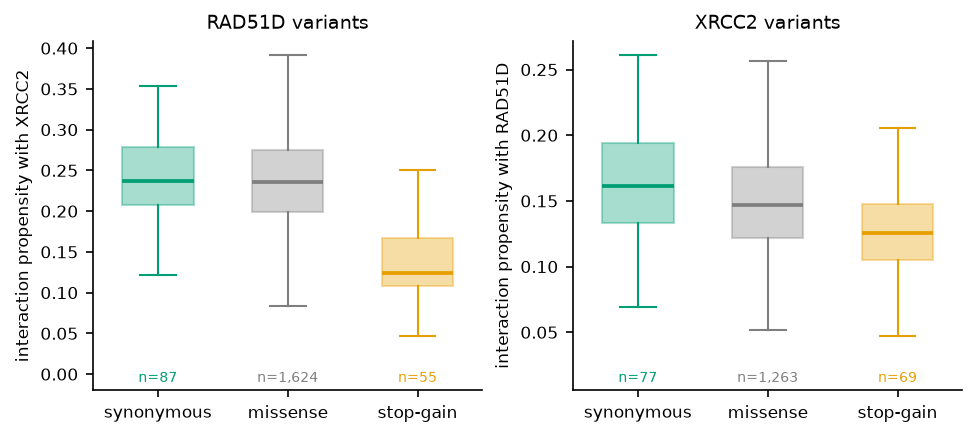

RAD51D median propensity: synonymous 0.2372, missense 0.2357, stop 0.1238; stop-gain below synonymous, Mann-Whitney p = 4.8e-14
XRCC2 median propensity: synonymous 0.1616, missense 0.1470, stop 0.1256; stop-gain below synonymous, Mann-Whitney p = 3.3e-06


In [12]:
figure, axes = plt.subplots(1, 2, figsize=(6.4, 2.8), constrained_layout=True)
for axis, (gene, scan) in zip(axes, SCANS.items()):
    table, sizes = scan["variants"], []
    for position, name in enumerate(ORDER):
        values = table.loc[table["class"] == name, "propensity_mean"]
        box(axis, position, values, CLASS_COLOR[name])
        sizes.append(len(values))
    count_labels(axis, sizes, [CLASS_COLOR[name] for name in ORDER])
    axis.set_xticks(range(len(ORDER)), ["synonymous", "missense", "stop-gain"])
    axis.set(ylabel=f"interaction propensity with {scan['partner']}",
             title=f"{gene} variants")
plt.show()

for gene, scan in SCANS.items():
    table = scan["variants"]
    medians = table.groupby("class")["propensity_mean"].median()
    contrast = sstats.mannwhitneyu(table.loc[table["class"] == "stop", "logit_mean"],
                                   table.loc[table["class"] == "synonymous", "logit_mean"],
                                   alternative="less")
    print(f"{gene} median propensity: "
          + ", ".join(f"{name} {medians[name]:.4f}" for name in ORDER)
          + f"; stop-gain below synonymous, Mann-Whitney p = {contrast.pvalue:.2g}")

The ordering holds in both scans.
The RAD51D medians read 0.237 for synonymous, 0.236 for missense and 0.124 for stop-gain; the XRCC2 medians read 0.162, 0.147 and 0.126.
Truncating RAD51D roughly halves the editing probability relative to leaving it intact.
The missense distribution sits close to the synonymous level with a long lower tail: most substitutions do nothing to an interaction and a minority matter.

The two scans differ in how much room they leave.
RAD51D-XRCC2 editing starts near 24% in the RAD51D library and near 16% in the XRCC2 library, and the stop-gain floor is correspondingly higher in the second.
A narrower gap between the synonymous level and the truncation floor is less dynamic range to detect a partial loss in, which is one reason the two scans call different numbers of variants in the next section.

## 6. Calling variants against the synonymous null

`pyroppi.stats.synonymous_test` tests every variant against its own gene's synonymous pool on the logit scale.
It takes the mean and standard deviation of the synonymous baselines, turns each variant's baseline into a z against them, and reads the normal lower tail.
A variant is called when that p falls under `alpha` and the variant is not itself synonymous.
The test is one-tailed and looks downward only, because the question is which substitutions lose the interaction.

Synonymous variants get a z and a p like any other row, which is what makes the null inspectable: the share of the synonymous pool that falls below the threshold is the test's realised false-positive rate on variants that should have no effect.

RAD51D: 70 of 1,624 missense called (4.3%), 30 of 55 stop-gain, 5.7% of the 87-variant synonymous null below p = 0.05, 7 missense surviving Benjamini-Hochberg
XRCC2: 30 of 1,263 missense called (2.4%), 3 of 69 stop-gain, 1.3% of the 77-variant synonymous null below p = 0.05, 0 missense surviving Benjamini-Hochberg


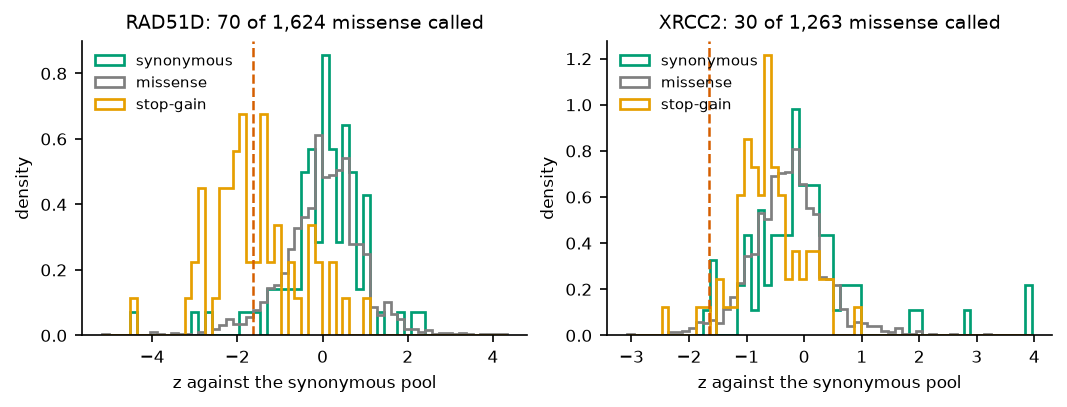

In [13]:
threshold = sstats.norm.ppf(ALPHA)

figure, axes = plt.subplots(1, 2, figsize=(7.0, 2.6), constrained_layout=True)
for axis, (gene, scan) in zip(axes, SCANS.items()):
    scan["tested"] = ps.synonymous_test(scan["variants"], score="logit_mean",
                                        by="gene", alpha=ALPHA)
    tested = scan["tested"]
    missense = tested["class"] == "missense"
    stop = tested["class"] == "stop"
    synonymous = tested["class"] == "synonymous"
    n_hit, n_missense = int(tested.loc[missense, "hit"].sum()), int(missense.sum())
    bh = ps.benjamini_hochberg(tested.loc[missense, "p"])
    print(f"{gene}: {n_hit} of {n_missense:,} missense called "
          f"({n_hit / n_missense:.1%}), "
          f"{int(tested.loc[stop, 'hit'].sum())} of {int(stop.sum())} stop-gain, "
          f"{(tested.loc[synonymous, 'p'] < ALPHA).mean():.1%} of the "
          f"{int(synonymous.sum())}-variant synonymous null below p = {ALPHA}, "
          f"{int((bh < ALPHA).sum())} missense surviving Benjamini-Hochberg")

    bins = np.linspace(tested["z"].min(), tested["z"].max(), 60)
    for name in ORDER:
        axis.hist(tested.loc[tested["class"] == name, "z"], bins=bins, density=True,
                  histtype="step", linewidth=1.3, color=CLASS_COLOR[name],
                  label=name.replace("stop", "stop-gain"))
    axis.axvline(threshold, color=HIT, linestyle="--", linewidth=1.2)
    axis.set(xlabel="z against the synonymous pool", ylabel="density",
             title=f"{gene}: {n_hit} of {n_missense:,} missense called")
    axis.legend(loc="upper left", fontsize=7)
plt.show()

Seventy of 1,624 RAD51D missense variants are called and 30 of 1,263 for XRCC2, which is 4.3% and 2.4%.
Both sit at or under the nominal 5% the threshold admits, and the synonymous pools behave: 5.7% of the 87 RAD51D synonymous variants fall below p = 0.05 and 1.3% of the 77 XRCC2 ones, so the null is calibrated to roughly its nominal rate in both.

The call count is not itself a result.
A test run at a 5% one-tailed threshold against a null of 87 variants will call about 5% of anything, so these lists are the right size to be consistent with no signal at all.
The stop-gain controls make the same point from the other side.
Thirty of 55 RAD51D stop-gain variants are called, as a truncation ought to be, and only 3 of 69 XRCC2 ones, which says the XRCC2 scan has less power to detect loss.
It does not say that truncating XRCC2 is tolerated.
Benjamini-Hochberg over the missense p-values is the stricter read and leaves seven RAD51D variants and none at all in XRCC2.
The next two sections look at where the called variants sit.

## 7. The position track and the Walker motifs

Plotting the result along the sequence maps the calls onto the protein.
Each point is one residue, plotted at the mean propensity of the missense substitutions assayed there, with the synonymous and stop-gain medians drawn across as the two reference levels.
Residues carrying at least one called variant are marked.

Both proteins are RecA-fold ATPases, so they carry a Walker A motif, the phosphate-binding P-loop, and a Walker B motif that coordinates the catalytic magnesium.
Those two motifs are the strongest prior the structure offers about where a substitution should matter, and they are marked on the track: RAD51D residues 107 to 114 and 200 to 210, XRCC2 residues 48 to 55 and 145 to 149.
Each motif is tested against the rest of the chain with a one-sided Mann-Whitney U on the logit, in the direction that the motif sits lower.

In [14]:
MOTIFS = {
    "RAD51D": {"Walker A": (107, 114), "Walker B": (200, 210)},
    "XRCC2": {"Walker A": (48, 55), "Walker B": (145, 149)},
}
annotation_columns = ["variant", "alphamissense", "alphamissense_class", "popEVE",
                      "min_dist_to_partner_A", "interface_8A", "conservation"]
annotations = pd.read_csv(DATA / "annotations" / "variants.csv")

for gene, scan in SCANS.items():
    tested = scan["tested"]
    scan["missense"] = tested[tested["class"] == "missense"].merge(
        annotations[annotation_columns], on="variant", how="left")

rows = []
for gene, scan in SCANS.items():
    missense = scan["missense"]
    for label, (low, high) in MOTIFS[gene].items():
        inside = missense["position"].between(low, high)
        result = sstats.mannwhitneyu(missense.loc[inside, "logit_mean"],
                                     missense.loc[~inside, "logit_mean"],
                                     alternative="less")
        rows.append({"gene": gene, "motif": label, "residues": f"{low}-{high}",
                     "n_variants": int(inside.sum()),
                     "n_hit": int(missense.loc[inside, "hit"].sum()),
                     "motif_median": missense.loc[inside, "propensity_mean"].median(),
                     "background_median": missense.loc[~inside, "propensity_mean"].median(),
                     "p": result.pvalue})
motifs = pd.DataFrame(rows)
motifs

,gene,motif,residues,n_variants,n_hit,motif_median,background_median,p
0,RAD51D,Walker A,107-114,21,2,0.210820,0.235988,0.022602
1,RAD51D,Walker B,200-210,57,7,0.207551,0.236988,0.000066
2,XRCC2,Walker A,48-55,38,2,0.128388,0.147528,0.013430
3,XRCC2,Walker B,145-149,21,2,0.124362,0.147634,0.004484


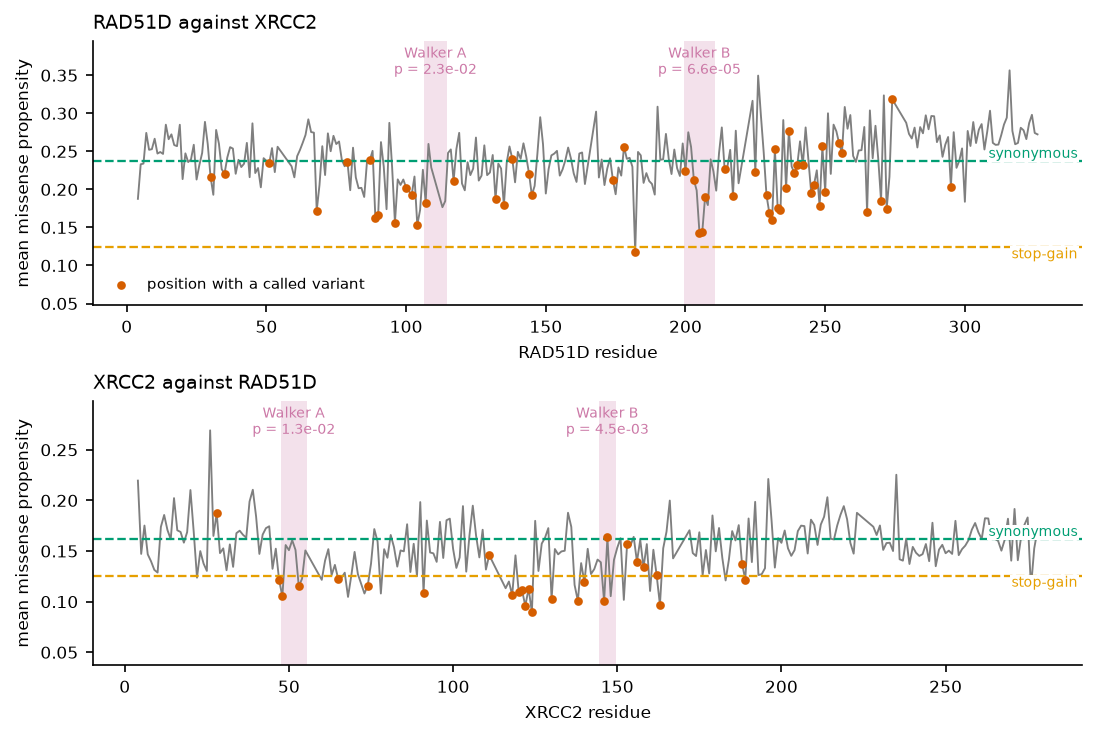

In [15]:
figure, axes = plt.subplots(2, 1, figsize=(7.2, 4.8), constrained_layout=True)
for axis, (gene, scan) in zip(axes, SCANS.items()):
    track = scan["missense"].groupby("position").agg(
        propensity=("propensity_mean", "mean"), n_hit=("hit", "sum"))
    reference = scan["tested"].groupby("class")["propensity_mean"].median()

    axis.plot(track.index, track["propensity"], color=MIS, linewidth=0.9)
    called = track[track["n_hit"] > 0]
    axis.scatter(called.index, called["propensity"], s=10, color=HIT, zorder=3,
                 label="position with a called variant")
    axis.axhline(reference["synonymous"], color=SYN, linestyle="--", linewidth=1.1)
    axis.axhline(reference["stop"], color=STOP, linestyle="--", linewidth=1.1)
    low, high = axis.get_ylim()
    axis.set_ylim(low - 0.22 * (high - low), high + 0.10 * (high - low))

    for label, (first, last) in MOTIFS[gene].items():
        axis.axvspan(first - 0.5, last + 0.5, color=WALKER, alpha=0.22, linewidth=0)
        p = motifs.loc[(motifs["gene"] == gene) & (motifs["motif"] == label), "p"].iloc[0]
        axis.text((first + last) / 2, 0.985, f"{label}\np = {p:.1e}",
                  transform=axis.get_xaxis_transform(), ha="center", va="top",
                  fontsize=6.5, color=WALKER)
    axis.set(xlabel=f"{gene} residue", ylabel="mean missense propensity",
             title=f"{gene} against {scan['partner']}")
    axis.title.set(ha="left", position=(0.0, 1.0))
    halo = dict(facecolor="white", edgecolor="none", pad=0.6)
    for level, label, colour, side in [
        (reference["synonymous"], "synonymous", SYN, "bottom"),
        (reference["stop"], "stop-gain", STOP, "top"),
    ]:
        axis.text(0.995, level, label, color=colour, fontsize=6.5, bbox=halo,
                  transform=axis.get_yaxis_transform(), ha="right", va=side)
axes[0].legend(loc="lower left", fontsize=7)
plt.show()

Both proteins have stretches where the average substitution is about as damaging as a truncation, and long stretches that sit at the synonymous level throughout.

All four Walker motifs come out below the rest of their chain and all four are significant: RAD51D Walker A at p = 0.023 over 21 variants and Walker B at p = 6.6e-05 over 57, XRCC2 Walker A at p = 0.013 over 38 variants and Walker B at p = 0.0045 over 21.
The motif medians sit between 0.025 and 0.03 of editing probability under their backgrounds in RAD51D and about 0.02 under in XRCC2, and only nine of the seventy RAD51D calls and four of the thirty XRCC2 calls fall inside a motif, so the shift is carried by the motifs' substitutions generally rather than by the called ones.
The Walker motifs were picked out of the fold before the scan was read, so finding them low is a check on the scan's sensitivity.
Nucleotide binding is a different thing from partner binding.
A P-loop substitution can reduce the measured interaction by destabilising the fold, by blocking the ATP that the complex assembles around, or by moving the partner surface, and the assay cannot separate those routes.
The scan is sensitive in the regions the structure says should matter.

## 8. Do the called variants sit closer to the partner?

The annotation table carries `min_dist_to_partner_A`, the shortest heavy-atom distance from each residue to the partner chain in PDB entry 9SVX.
If PPI Recorder is reporting on binding rather than on general protein damage, the variants it calls should sit nearer the partner than the variants it does not.
The test uses that distance as a continuous value, which keeps the whole ordering instead of reducing each residue to inside or outside a cutoff.

A structure measures residues and the assay measures variants, so the variants collapse to positions first.
Each resolved position contributes `n_hit` hit slots and `n_assayed - n_hit` non-hit slots, all at that position's distance.
The statistic is the non-hit mean distance minus the hit mean distance, weighted by those slots, so a positive number means the calls are nearer the partner.

The p-value for that gap needs care.
Hits do not fall on independent residues; they fall in contiguous runs along the chain, because a sensitive region is sensitive for several residues together, and structural features run in stretches for the same geometric reason.
Shuffling a per-position label breaks up the clustering of the hits while leaving the clustering of the distances intact, so the permuted datasets are less clumpy than the real one and the observation looks extreme against them.
Tested against data with no signal, that null rejects at 11 to 28% where its nominal rate is 5%, a figure recorded in the `pyroppi.stats` source.
`pyroppi.stats.run_replacement_test` takes the contiguous runs of hit-carrying positions as they are, keeps their number, their lengths and the counts inside them, and only slides them to new places along the same chain, so the clumpiness of the hits is held fixed and only their location varies.

RAD51D: over 293 resolved residues carrying 70 hit slots and 1,496 non-hit slots, the called variants sit 10.87 Å from XRCC2 and the rest 14.42 Å, a gap of +3.55 Å at run-replacement p = 0.0022


XRCC2: over 225 resolved residues carrying 30 hit slots and 1,057 non-hit slots, the called variants sit 7.63 Å from RAD51D and the rest 10.82 Å, a gap of +3.19 Å at run-replacement p = 0.0095


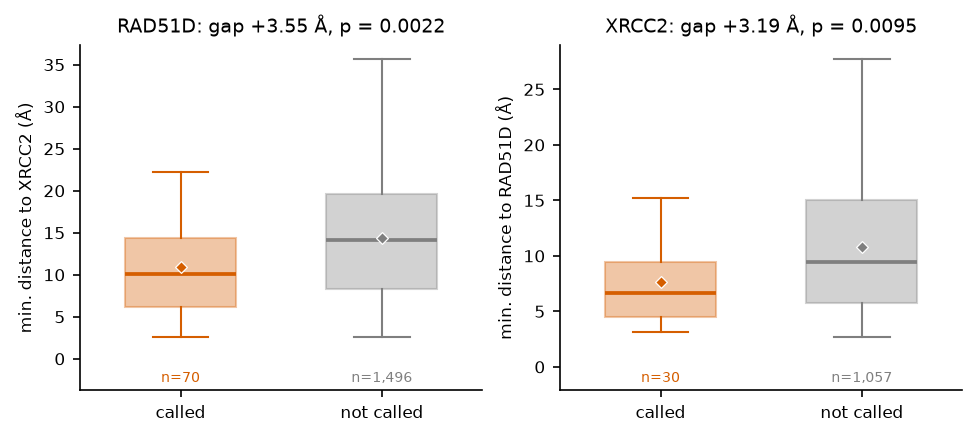

In [16]:
figure, axes = plt.subplots(1, 2, figsize=(6.4, 2.8), constrained_layout=True)
for axis, (gene, scan) in zip(axes, SCANS.items()):
    resolved = scan["missense"][scan["missense"]["min_dist_to_partner_A"].notna()]
    profile = (resolved.groupby("position")
               .agg(n_hit=("hit", "sum"), n_assayed=("hit", "size"),
                    distance=("min_dist_to_partner_A", "first"))
               .reset_index().sort_values("position"))
    distance = profile["distance"].to_numpy(float)
    n_hit = profile["n_hit"].to_numpy(int)
    n_assayed = profile["n_assayed"].to_numpy(int)

    def gap(hit_slots, assayed_slots, distance=distance):
        other = assayed_slots - hit_slots
        return float(other @ distance / other.sum()
                     - hit_slots @ distance / hit_slots.sum())

    observed, p_value = ps.run_replacement_test(
        np.full(len(profile), gene), n_hit, n_assayed, gap, draws=DRAWS, seed=SEED)

    other = n_assayed - n_hit
    print(f"{gene}: over {len(profile)} resolved residues carrying {n_hit.sum()} hit "
          f"slots and {other.sum():,} non-hit slots, the called variants sit "
          f"{n_hit @ distance / n_hit.sum():.2f} Å from {scan['partner']} and the rest "
          f"{other @ distance / other.sum():.2f} Å, a gap of {observed:+.2f} Å at "
          f"run-replacement p = {p_value:.4f}")

    sizes = []
    for position, (subset, colour) in enumerate([(resolved[resolved["hit"]], HIT),
                                                 (resolved[~resolved["hit"]], MIS)]):
        values = subset["min_dist_to_partner_A"].to_numpy()
        box(axis, position, values, colour)
        axis.scatter(position, values.mean(), marker="D", s=16, color=colour,
                     edgecolors="white", linewidths=0.6, zorder=4)
        sizes.append(len(values))
    count_labels(axis, sizes, [HIT, MIS])
    axis.set_xticks([0, 1], ["called", "not called"])
    axis.set(ylabel=f"min. distance to {scan['partner']} (Å)",
             title=f"{gene}: gap {observed:+.2f} Å, p = {p_value:.4f}")
plt.show()

Both scans give the same answer.
The RAD51D calls sit 3.55 Å closer to XRCC2 than the rest, 10.87 Å against 14.42 Å, over 293 resolved residues carrying 70 hit slots, at a run-replacement p of 0.0022.
The XRCC2 calls sit 3.19 Å closer to RAD51D, 7.63 Å against 10.82 Å, over 225 resolved residues carrying 30 hit slots, at p of 0.0095.
The diamonds on the boxes are those means, which are the quantities the statistic compares; the boxes themselves show how wide the two distributions are around them.

`scripts/figure_4.py` computes the same contrast for the manuscript panel and prints it split by AlphaMissense class as well.
Its "all variants" rows match the two numbers above, 3.5530 Å at p = 0.0022 for RAD51D and 3.1943 Å at p = 0.0095 for XRCC2, which is expected: the vignette runs the same statistic at the same 20,000 draws and the same seed over the same variants.
The split rows add that the gap is larger among the variants AlphaMissense calls benign, 6.20 Å for RAD51D and 4.14 Å for XRCC2, and is not significant among the ones it calls pathogenic.
The calls AlphaMissense would not flag are therefore the ones sitting closest to the partner, which is what the manuscript panel reports.